# 03 · Validate the Poisson GAM

**This notebook trains fresh GAMs with selected measurements held out.** It
reuses the cleaned June 1 bins and `src/fit_profile.py`. Raw recordings, cleaned
CSVs and notebook 02's baseline models stay unchanged.

Use **Python (HERA)**. Start with a fresh kernel and run all cells in order.
Place this notebook in your repository's `notebooks/` folder. No additional
packages are required beyond the environment used for notebook 02.

This is an **exploratory within-flight interpolation check**: can a curve fitted
on the surrounding observations predict missing time blocks? It is not a
future-flight test or a physical calibration. June 1 has already been inspected
during development, so these scores are not a pristine, previously unseen final
test. Peak-location uncertainty is not calculated here.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import pickle
import platform
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Image

here = Path.cwd().resolve()
ROOT = next((p for p in (here, *here.parents)
             if (p / "src/fit_profile.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Place this notebook inside HERA-Machine-Learning/notebooks.")
sys.path.insert(0, str(ROOT / "src"))
import fit_profile
import matplotlib.pyplot as plt

if not all(hasattr(fit_profile, name) for name in ("load_bins", "fit_phase", "fingerprint")):
    raise RuntimeError("Use the fit_profile.py supplied with notebooks 01 and 02.")
VERSIONS = {"python": platform.python_version(), **{
    name: version(name) for name in ("pygam", "numpy", "pandas", "scipy", "matplotlib")}}
print("Project:", ROOT)
print("Python:", sys.executable)
print("Versions:", VERSIONS)

Project: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning
Python: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\.venv\Scripts\python.exe
Versions: {'python': '3.13.3', 'pygam': '0.12.0', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scipy': '1.16.3', 'matplotlib': '3.11.2'}


## 1. Keep the agreed baseline settings

The defaults hold out about **20% of phase duration** in three internal time
blocks, centered at 20%, 50% and 80% of each detector/phase's retained time span.
Complete bins inside those windows are test rows. Bins crossing a window edge,
or overlapping its **30-second buffer** on either side, are withheld from
training too. The actual fraction of test bins can differ from 20%.

Thirty seconds is a working buffer choice, not a verified decorrelation time.
Agree on it before looking at test scores. Each detector uses its own clock;
fractional windows do not synchronize the detectors.

Use `elapsed` initially, as in notebook 02. It assumes continuous acquisition.
`candidate-live` adds the unverified cumulative-deadtime assumption. Keep
detectors, phases and event channels separate. Smoothing is selected by the
existing fitter's UBRE criterion on **training rows only**. No test rows are
used for spline knots, coefficient fitting or smoothing selection.

In [ ]:
FLIGHT_ID = "2026-05-31"
DETECTORS = ["left", "middle", "right"]
BIN_SECONDS = 10
CHANNEL = "all"
EXPOSURE = "elapsed"
N_SPLINES = 12
FIXED_LAMBDA = None

TEST_BLOCK_CENTERS = [0.20, 0.50, 0.80]
TEST_TIME_FRACTION = 0.20
GAP_SECONDS = 30.0

# Leave empty for the latest matching prepared tables, or pin exact input paths.
# Example: {"top": "clean/2025-06-01/RUN_ID/top_bins_10s.csv"}
INPUT_OVERRIDES = {}

## 2. Load the same cleaned measurements

This uses notebook 02's inclusion rules: ascent/descent only, no phase-crossing
bins, valid pressure/depth, and no pressure flags in a retained bin. Valid
zero-count bins are retained. `training_ready=False` remains a scientific-review
flag; it is not changed by exploratory fitting.

The exact source paths, hashes, preparation reports and chosen settings are
recorded. For an exact rerun, pin the printed paths in `INPUT_OVERRIDES`.

In [3]:
def positive_finite(value):
    return np.isfinite(value) and value > 0

if CHANNEL not in ("all", "coincident") or EXPOSURE not in fit_profile.EXPOSURES:
    raise ValueError("Check CHANNEL and EXPOSURE.")
if not positive_finite(BIN_SECONDS):
    raise ValueError("BIN_SECONDS must be positive and finite.")
if not DETECTORS or len(DETECTORS) != len(set(DETECTORS)):
    raise ValueError("Choose detectors without duplicates.")
if not isinstance(N_SPLINES, int) or N_SPLINES < 4:
    raise ValueError("N_SPLINES must be an integer of at least four.")
if FIXED_LAMBDA is not None and not positive_finite(FIXED_LAMBDA):
    raise ValueError("FIXED_LAMBDA must be positive and finite, or None.")
if not np.isfinite(GAP_SECONDS) or GAP_SECONDS < 0:
    raise ValueError("GAP_SECONDS must be finite and nonnegative.")
centers = np.asarray(TEST_BLOCK_CENTERS, dtype=float)
if (centers.ndim != 1 or len(centers) == 0 or not np.isfinite(centers).all()
        or (np.diff(centers) <= 0).any()):
    raise ValueError("TEST_BLOCK_CENTERS must be a nonempty, increasing list.")
if not np.isfinite(TEST_TIME_FRACTION) or not 0 < TEST_TIME_FRACTION < 1:
    raise ValueError("TEST_TIME_FRACTION must be between zero and one.")
half_fraction = TEST_TIME_FRACTION / (2 * len(centers))
if ((centers - half_fraction <= 0).any() or (centers + half_fraction >= 1).any()
        or (np.diff(centers) <= 2 * half_fraction).any()):
    raise ValueError("Test windows must be separate and strictly inside the phase.")

# Snapshot settings once so subsequent cells use a consistent experiment.
settings = {"flight_id": FLIGHT_ID, "detectors": list(DETECTORS),
    "bin_seconds": float(BIN_SECONDS), "channel": CHANNEL, "exposure": EXPOSURE,
    "test_block_centers": centers.tolist(), "test_time_fraction": float(TEST_TIME_FRACTION),
    "gap_seconds": float(GAP_SECONDS)}
model_settings = {"n_splines": N_SPLINES, "fixed_lambda": FIXED_LAMBDA,
    "lambda_grid": fit_profile.LAMBDA_GRID.tolist() if FIXED_LAMBDA is None
                   else [float(FIXED_LAMBDA)],
    "smoothing_selection": "training-only UBRE" if FIXED_LAMBDA is None else "fixed in advance"}

selected_data, excluded_parts, input_records, selection_rows = {}, [], {}, []
for detector in settings["detectors"]:
    if detector in INPUT_OVERRIDES:
        chosen = ROOT / Path(INPUT_OVERRIDES[detector])
    else:
        pattern = f"*/{detector}_bins_{settings['bin_seconds']:g}s.csv"
        candidates = sorted((ROOT / "clean" / settings["flight_id"]).glob(pattern))
        if not candidates:
            raise FileNotFoundError(f"Run notebook 01 for {detector}, {BIN_SECONDS}s bins first.")
        chosen = candidates[-1]
    chosen = chosen.resolve()
    before_hash = fit_profile.fingerprint(chosen)
    frame = fit_profile.load_bins(chosen, settings["channel"], settings["exposure"])
    if not (frame.flight_id.eq(settings["flight_id"]).all()
            and frame.detector_id.eq(detector).all()
            and np.allclose(frame.elapsed_s, settings["bin_seconds"])):
        raise ValueError(f"Input identity or bin width does not match: {chosen}")
    report_path = ROOT / "results" / settings["flight_id"] / chosen.parent.name / "preparation_report.json"
    if not report_path.is_file():
        raise FileNotFoundError(f"Keep the paired preparation report from notebook 01: {report_path}")
    prep = json.loads(report_path.read_text(encoding="utf-8"))
    if (prep["config"]["flight_id"], prep["config"]["detector_id"]) != (settings["flight_id"], detector):
        raise ValueError("Preparation report identity mismatch.")
    if fit_profile.fingerprint(chosen) != before_hash:
        raise RuntimeError("Input changed while it was being read; restart this run.")
    input_records[detector] = {"csv": str(chosen), "csv_sha256": before_hash,
        "preparation_report": str(report_path), "source_sha256": prep["source_sha256"],
        "preparation_config": prep["config"],
        "input_training_ready_false": int((~frame.training_ready).sum())}
    included = frame.loc[frame.fit_selection.eq("included")].copy()
    if not set(fit_profile.PHASES).issubset(set(included.phase_provisional)):
        raise ValueError(f"Both ascent and descent are required for {detector}.")
    selected_data[detector] = included
    excluded_parts.append(frame.loc[~frame.fit_selection.eq("included")].copy())
    selection_rows.append({"detector": detector, **{
        str(k): int(v) for k, v in frame.fit_selection.value_counts().items()}})
    print(detector.upper(), "input:", chosen)
display(pd.DataFrame(selection_rows).fillna(0))

TOP input: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\clean\2025-06-01\20261101T015111272348Z\top_bins_10s.csv
BOTTOM input: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\clean\2025-06-01\20261101T015118154929Z\bottom_bins_10s.csv


,detector,outside_ascent_descent,included,flagged_pressure_in_bin
0,top,1121,796,2.0
1,bottom,1120,798,0.0


## 3. Create and inspect the split before training

`train` rows are available to the fitter. `test` rows are withheld. `gap` rows
protect the temporal boundary and are used for neither fitting nor scoring.
The row IDs and input hashes make the exact split shareable and reproducible.
No count values are used to choose a test window.

In [4]:
def make_blocked_split(data, centers, fraction, gap_seconds, n_splines):
    result = data.sort_values("bin_start_s").copy().reset_index(drop=True)
    a = result.bin_start_s.to_numpy(dtype=float)
    b = result.bin_end_s.to_numpy(dtype=float)
    start, stop = float(a.min()), float(b.max())
    span = stop - start
    half = fraction * span / (2 * len(centers))
    windows = [(start + float(c) * span - half, start + float(c) * span + half)
               for c in centers]
    if any(windows[i][1] + gap_seconds >= windows[i+1][0] - gap_seconds
           for i in range(len(windows)-1)):
        raise ValueError("Buffered test windows overlap; review the pre-agreed split settings.")
    roles = np.full(len(result), "train", dtype=object)
    block_ids = np.zeros(len(result), dtype=int)
    window_records = []
    for block_id, (lower, upper) in enumerate(windows, start=1):
        protected = (a < upper + gap_seconds) & (b > lower - gap_seconds)
        inside = (a >= lower) & (b <= upper)
        if not inside.any():
            raise ValueError("A test window has no complete bins; review bin width and split settings.")
        roles[protected] = "gap"
        roles[inside] = "test"
        block_ids[inside] = block_id
        window_records.append({"test_block": block_id, "start_s": lower, "end_s": upper,
            "buffer_start_s": lower - gap_seconds, "buffer_end_s": upper + gap_seconds,
            "test_bins": int(inside.sum())})
    result["split_role"] = roles
    result["test_block"] = block_ids
    train = result.loc[result.split_role.eq("train")]
    test = result.loc[result.split_role.eq("test")]
    if len(train) < max(30, n_splines + 5) or train.depth_g_cm2.nunique() < n_splines:
        raise ValueError("Too few training bins or distinct depths; review the pre-agreed split.")
    if len(test) < 5:
        raise ValueError("Too few test bins for a useful evaluation.")
    # Verify every pair of training/test intervals has the requested separation.
    ta, tb = train.bin_start_s.to_numpy(), train.bin_end_s.to_numpy()
    va, vb = test.bin_start_s.to_numpy(), test.bin_end_s.to_numpy()
    separation = np.maximum(va[:, None] - tb[None, :], ta[None, :] - vb[:, None])
    if np.min(separation) < gap_seconds - 1e-7:
        raise AssertionError("Training and test bins violate the requested time buffer.")
    result["outside_training_depth_range"] = (
        (result.depth_g_cm2 < train.depth_g_cm2.min())
        | (result.depth_g_cm2 > train.depth_g_cm2.max()))
    return result, window_records

split_parts, split_windows, summary_rows = [], [], []
for detector, included in selected_data.items():
    for phase in fit_profile.PHASES:
        part, windows = make_blocked_split(
            included.loc[included.phase_provisional.eq(phase)],
            settings["test_block_centers"], settings["test_time_fraction"],
            settings["gap_seconds"], model_settings["n_splines"])
        part["log_depth"] = np.log(part.depth_g_cm2)
        part["row_id"] = [f"{settings['flight_id']}:{detector}:{a:.12g}:{b:.12g}"
                          for a, b in zip(part.bin_start_s, part.bin_end_s)]
        split_parts.append(part)
        split_windows.extend({"detector": detector, "phase": phase, **w} for w in windows)
        counts = part.split_role.value_counts().to_dict()
        summary_rows.append({"detector": detector, "phase": phase,
            "train_bins": int(counts.get("train", 0)), "gap_bins": int(counts.get("gap", 0)),
            "test_bins": int(counts.get("test", 0)),
            "test_fraction_of_eligible_bins": float(part.split_role.eq("test").mean()),
            "test_bins_outside_training_depth_range": int(
                (part.split_role.eq("test") & part.outside_training_depth_range).sum())})
split_data = pd.concat(split_parts, ignore_index=True)
if not split_data.row_id.is_unique:
    raise ValueError("Duplicate row IDs in the benchmark.")
split_summary = pd.DataFrame(summary_rows)
display(split_summary.round(3))
display(pd.DataFrame(split_windows).round(2))
if split_summary.test_bins_outside_training_depth_range.sum():
    print("Some test depths require extrapolation. Their flags are retained in the predictions.")

,detector,phase,train_bins,gap_bins,test_bins,test_fraction_of_eligible_bins,test_bins_outside_training_depth_range
0,top,ascent,464,24,119,0.196,0
1,top,descent,130,24,35,0.185,0
2,bottom,ascent,466,24,119,0.195,0
3,bottom,descent,130,24,35,0.185,0


,detector,phase,test_block,start_s,end_s,buffer_start_s,buffer_end_s,test_bins
0,top,ascent,1,4225.0,4631.0,4195.0,4661.0,40
1,top,ascent,2,6052.0,6458.0,6022.0,6488.0,39
2,top,ascent,3,7879.0,8285.0,7849.0,8315.0,40
3,top,descent,1,9615.0,9741.0,9585.0,9771.0,12
4,top,descent,2,10182.0,10308.0,10152.0,10338.0,11
5,top,descent,3,10749.0,10875.0,10719.0,10905.0,12
6,bottom,ascent,1,4225.0,4631.0,4195.0,4661.0,40
7,bottom,ascent,2,6052.0,6458.0,6022.0,6488.0,39
8,bottom,ascent,3,7879.0,8285.0,7849.0,8315.0,40
9,bottom,descent,1,9615.0,9741.0,9585.0,9771.0,12


In [5]:
fig, axes = plt.subplots(len(settings["detectors"]), 2,
                         figsize=(12, 3.4 * len(settings["detectors"])), squeeze=False)
colors = {"train": "#3268a8", "test": "#dc781b", "gap": "#b9bec5"}
for row, detector in enumerate(settings["detectors"]):
    for col, phase in enumerate(fit_profile.PHASES):
        ax = axes[row, col]
        part = split_data.loc[split_data.detector_id.eq(detector)
                              & split_data.phase_provisional.eq(phase)]
        for role in ("train", "gap", "test"):
            shown = part.loc[part.split_role.eq(role)]
            ax.scatter((shown.bin_start_s + shown.bin_end_s) / 120,
                       shown.depth_g_cm2, s=10, color=colors[role], label=role)
        ax.set(title=f"{detector.capitalize()} · {phase}",
               xlabel="Own detector elapsed time [minutes]", ylabel="Atmospheric depth [g/cm²]")
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Blocked holdout: rows used for training, testing and temporal buffers")
fig.tight_layout(rect=(0, 0, 1, 0.95))
split_figure = fig
display(fig)
plt.close(fig)

<Figure size 1200x680 with 4 Axes>

## 4. Save the benchmark for both models

Every full run makes a new `results/FLIGHT/TIMESTAMP_gam_validation/` folder.
`benchmark_bins.csv` contains eligible bins, their roles, the target
`counts_used`, exposure `exposure_s_used`, and input `log_depth`.
`excluded_bins.csv` records measurements excluded before splitting.

The benchmark ID depends on the inputs, selection rules and split, not the
model's hyperparameters. Identical inputs/settings reproduce that ID. Share
these frozen rows with your colleague instead of generating separate splits.

In [6]:
assignment_bytes = split_data[["row_id", "split_role", "test_block"]].sort_values("row_id").to_csv(index=False).encode()
benchmark_spec = {"schema_version": 1, "settings": settings,
    "input_csv_sha256": {d: r["csv_sha256"] for d, r in sorted(input_records.items())},
    "selection_rule": "included rows from fit_profile.load_bins; include_flagged=False",
    "assignment_sha256": hashlib.sha256(assignment_bytes).hexdigest(), "windows": split_windows}
benchmark_id = hashlib.sha256(json.dumps(benchmark_spec, sort_keys=True, allow_nan=False).encode()).hexdigest()[:20]
split_data.insert(0, "benchmark_id", benchmark_id)
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR = ROOT / "results" / settings["flight_id"] / f"{stamp}_gam_validation"
RUN_DIR.mkdir(parents=True, exist_ok=False)
benchmark_columns = ["benchmark_id", "row_id", "flight_id", "detector_id", "phase_provisional",
    "source_csv_row", "bin_start_s", "bin_end_s", "split_role", "test_block",
    "counts_used", "exposure_s_used", "elapsed_s", "pressure_pa", "depth_g_cm2", "log_depth",
    "outside_training_depth_range", "training_ready"]
split_data[benchmark_columns].to_csv(RUN_DIR / "benchmark_bins.csv", index=False)
pd.concat(excluded_parts, ignore_index=True).to_csv(RUN_DIR / "excluded_bins.csv", index=False)
split_summary.to_csv(RUN_DIR / "split_summary.csv", index=False)
split_figure.savefig(RUN_DIR / "split_plan.png", dpi=150)
manifest = {"status": "benchmark_saved_models_not_trained", "benchmark_id": benchmark_id,
    "created_at_utc": datetime.now(timezone.utc).isoformat(), "benchmark_spec": benchmark_spec,
    "inputs": input_records, "model_settings": model_settings, "versions": VERSIONS,
    "fitter_sha256": fit_profile.fingerprint(fit_profile.__file__),
    "limitations": [
        "Exploratory within-flight interpolation, not future forecasting or new-flight validation.",
        "June 1 was already inspected in development; this is not a pristine final test.",
        "The 30-second default buffer is a working assumption, not a verified decorrelation time.",
        "Pressure, timing, phase boundaries, acquisition continuity and calibration remain provisional.",
        "Separate detector clocks are not synchronized by this split.",
        "No peak-location confidence interval or calibrated altitude is produced."
    ]}
def save_manifest():
    (RUN_DIR / "split_manifest.json").write_text(
        json.dumps(manifest, indent=2, allow_nan=False), encoding="utf-8")
save_manifest()
print("Benchmark:", benchmark_id)
print("Outputs:", RUN_DIR)

Benchmark: 377399ea5ad99922a951
Outputs: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\results\2025-06-01\20261101T021517195014Z_gam_validation


## 5. Train fresh GAMs using only training rows

**This cell performs the retraining.** It does not load the full-data fitted
models from notebook 02. The same fitter receives only `split_role == "train"`.
Its smoothing candidates and spline construction therefore see no test rows.

A constant-rate reference is also estimated from training counts/exposure. It
gives a simple comparison: does the pressure-dependent GAM improve on predicting
one average rate throughout a phase? Test measurements are used only afterward
to calculate errors. Keep test rows out of all further tuning and early stopping.

In [7]:
def prediction_frame(model, data, constant_rate):
    result = data.copy()
    x = result.log_depth.to_numpy(dtype=float)[:, None]
    exposure = result.exposure_s_used.to_numpy(dtype=float)
    predicted_counts = np.asarray(model.predict(x, exposure=exposure))
    predicted_rate = np.asarray(model.predict(x))
    if (not np.isfinite(predicted_counts).all() or (predicted_counts <= 0).any()
            or not np.allclose(predicted_counts, predicted_rate * exposure)):
        raise ValueError("Invalid GAM prediction or inconsistent exposure units.")
    result["observed_rate_cps"] = result.counts_used / result.exposure_s_used
    result["predicted_rate_cps"] = predicted_rate
    result["predicted_counts"] = predicted_counts
    result["constant_rate_cps"] = constant_rate
    result["constant_expected_counts"] = constant_rate * exposure
    result["rate_residual_cps"] = result.observed_rate_cps - predicted_rate
    return result

def score_predictions(data, predicted_counts):
    y = data.counts_used.to_numpy(dtype=float)
    exposure = data.exposure_s_used.to_numpy(dtype=float)
    mu = np.asarray(predicted_counts, dtype=float)
    if not len(y) or mu.shape != y.shape or not np.isfinite(mu).all() or (mu <= 0).any():
        raise ValueError("Scoring requires nonempty rows and finite positive expected counts.")
    difference = (y - mu) / exposure
    terms = np.zeros_like(y)
    positive = y > 0
    terms[positive] = y[positive] * np.log(y[positive] / mu[positive])
    deviance = 2 * np.maximum(terms - y + mu, 0)
    return {"bins": int(len(data)), "events": int(y.sum()),
        "exposure_seconds": float(exposure.sum()),
        "mae_cps": float(np.mean(np.abs(difference))),
        "rmse_cps": float(np.sqrt(np.mean(difference**2))),
        "mean_poisson_deviance": float(np.mean(deviance))}

models, diagnostic_records, prediction_parts, curve_parts, metric_rows, block_rows = {}, {}, [], [], [], []
for detector in settings["detectors"]:
    for phase in fit_profile.PHASES:
        group = split_data.loc[split_data.detector_id.eq(detector)
                               & split_data.phase_provisional.eq(phase)].copy()
        train = group.loc[group.split_role.eq("train")].copy()
        test = group.loc[group.split_role.eq("test")].copy()
        if set(train.row_id) & set(test.row_id):
            raise AssertionError("Training/test row overlap.")
        key = f"{detector}_{phase}"
        print(f"TRAINING {key}: {len(train)} bins; holding out {len(test)} test bins", flush=True)
        model, _, curve, stats = fit_profile.fit_phase(
            train, model_settings["n_splines"], model_settings["fixed_lambda"])
        models[key] = model
        diagnostic_records[key] = stats
        curve["detector_id"] = detector
        curve_parts.append(curve)
        constant_rate = float(train.counts_used.sum() / train.exposure_s_used.sum())
        for role, subset in (("train", train), ("test", test)):
            predicted = prediction_frame(model, subset, constant_rate)
            prediction_parts.append(predicted)
            gam_metrics = score_predictions(predicted, predicted.predicted_counts)
            constant_metrics = score_predictions(predicted, predicted.constant_expected_counts)
            base_deviance = constant_metrics["mean_poisson_deviance"]
            metric_rows.append({"detector": detector, "phase": phase, "split_role": role,
                **gam_metrics, "constant_mae_cps": constant_metrics["mae_cps"],
                "constant_rmse_cps": constant_metrics["rmse_cps"],
                "constant_mean_poisson_deviance": base_deviance,
                "deviance_reduction_vs_constant": (1 - gam_metrics["mean_poisson_deviance"] / base_deviance)
                    if base_deviance > 0 else None,
                "selected_lambda": stats["selected_lambda"],
                "lambda_at_grid_boundary": stats["selected_lambda"] in
                    (min(model_settings["lambda_grid"]), max(model_settings["lambda_grid"]))
                    if model_settings["fixed_lambda"] is None else False,
                "test_depths_outside_training_range": int(test.outside_training_depth_range.sum())})
            if role == "test":
                for block_id, block in predicted.groupby("test_block"):
                    block_rows.append({"detector": detector, "phase": phase,
                        "test_block": int(block_id), **score_predictions(block, block.predicted_counts)})

predictions = pd.concat(prediction_parts, ignore_index=True)
curves = pd.concat(curve_parts, ignore_index=True)
metrics = pd.DataFrame(metric_rows)
test_metrics = metrics.loc[metrics.split_role.eq("test")].copy()
for detector, record in input_records.items():
    if fit_profile.fingerprint(record["csv"]) != record["csv_sha256"]:
        raise RuntimeError(f"{detector} input changed during the run; results cannot be finalized.")
predictions.loc[predictions.split_role.eq("test")].to_csv(RUN_DIR / "test_predictions.csv", index=False)
predictions.loc[predictions.split_role.eq("train")].to_csv(RUN_DIR / "train_predictions.csv", index=False)
metrics.to_csv(RUN_DIR / "metrics.csv", index=False)
test_metrics.to_csv(RUN_DIR / "test_metrics.csv", index=False)
pd.DataFrame(block_rows).to_csv(RUN_DIR / "test_block_metrics.csv", index=False)
curves.to_csv(RUN_DIR / "training_fit_curves.csv", index=False)
(RUN_DIR / "training_fit_diagnostics.json").write_text(
    json.dumps(diagnostic_records, indent=2, allow_nan=False), encoding="utf-8")
manifest["status"] = "models_trained_and_scored"
with (RUN_DIR / "gam_models.pkl").open("wb") as handle:
    pickle.dump({"models": models, "metadata": manifest}, handle, protocol=pickle.HIGHEST_PROTOCOL)
save_manifest()
print("Saved fresh training-only models and held-out predictions.")

TRAINING top_ascent: 464 bins; holding out 119 test bins
TRAINING top_descent: 130 bins; holding out 35 test bins
TRAINING bottom_ascent: 466 bins; holding out 119 test bins
TRAINING bottom_descent: 130 bins; holding out 35 test bins
Saved fresh training-only models and held-out predictions.


## 6. Read the held-out scores

For **MAE**, **RMSE** and **mean Poisson deviance**, lower is better. MAE/RMSE
measure rate errors in counts per second; Poisson deviance compares observed
counts with expected counts for each bin's exposure. Scores must be compared on
identical rows and units. They are not an accuracy percentage or peak-location
error. No universal pass/fail threshold is imposed.

The constant-rate columns are the training-derived reference. Positive deviance
reduction means the GAM improves on that reference. Individual time blocks may
behave differently; inspect the block table and plots too. A smoothing choice
at a grid boundary is recorded for later **training-only** investigation.

In [8]:
display(test_metrics[["detector", "phase", "bins", "mae_cps", "rmse_cps",
    "mean_poisson_deviance", "constant_mae_cps", "constant_mean_poisson_deviance",
    "deviance_reduction_vs_constant", "selected_lambda", "lambda_at_grid_boundary"]].round(4))
print("Per-block held-out errors:")
display(pd.DataFrame(block_rows).round(4))
print("Training and test scores are both saved in metrics.csv; use test_metrics.csv for comparison.")

,detector,phase,bins,mae_cps,rmse_cps,mean_poisson_deviance,constant_mae_cps,constant_mean_poisson_deviance,deviance_reduction_vs_constant,selected_lambda,lambda_at_grid_boundary
1,top,ascent,119,1.2679,1.7134,1.1038,13.3986,92.1990,0.9880,0.01,True
3,top,descent,35,0.9706,1.2633,0.8374,14.5396,162.8820,0.9949,0.01,True
5,bottom,ascent,119,1.3434,1.6992,1.1204,12.4961,84.0505,0.9867,0.01,True
7,bottom,descent,35,1.6230,2.1659,1.9692,13.8304,151.8751,0.9870,0.01,True


Per-block held-out errors:


,detector,phase,test_block,bins,events,exposure_seconds,mae_cps,rmse_cps,mean_poisson_deviance
0,top,ascent,1,40,3031,400.0,0.7370,0.9294,1.1645
1,top,ascent,2,39,15858,390.0,1.7163,2.1841,1.1722
2,top,ascent,3,40,12968,400.0,1.3616,1.7941,0.9765
3,top,descent,1,12,4997,120.0,1.6480,1.7439,0.7316
4,top,descent,2,11,1761,110.0,0.9652,1.2716,0.9855
5,top,descent,3,12,212,120.0,0.2981,0.3621,0.8076
6,bottom,ascent,1,40,2958,400.0,0.7513,0.9038,1.1600
7,bottom,ascent,2,39,14751,390.0,1.8836,2.2972,1.3699
8,bottom,ascent,3,40,12477,400.0,1.4088,1.6209,0.8376
9,bottom,descent,1,12,4720,120.0,2.8981,3.1500,2.4166


Training and test scores are both saved in metrics.csv; use test_metrics.csv for comparison.


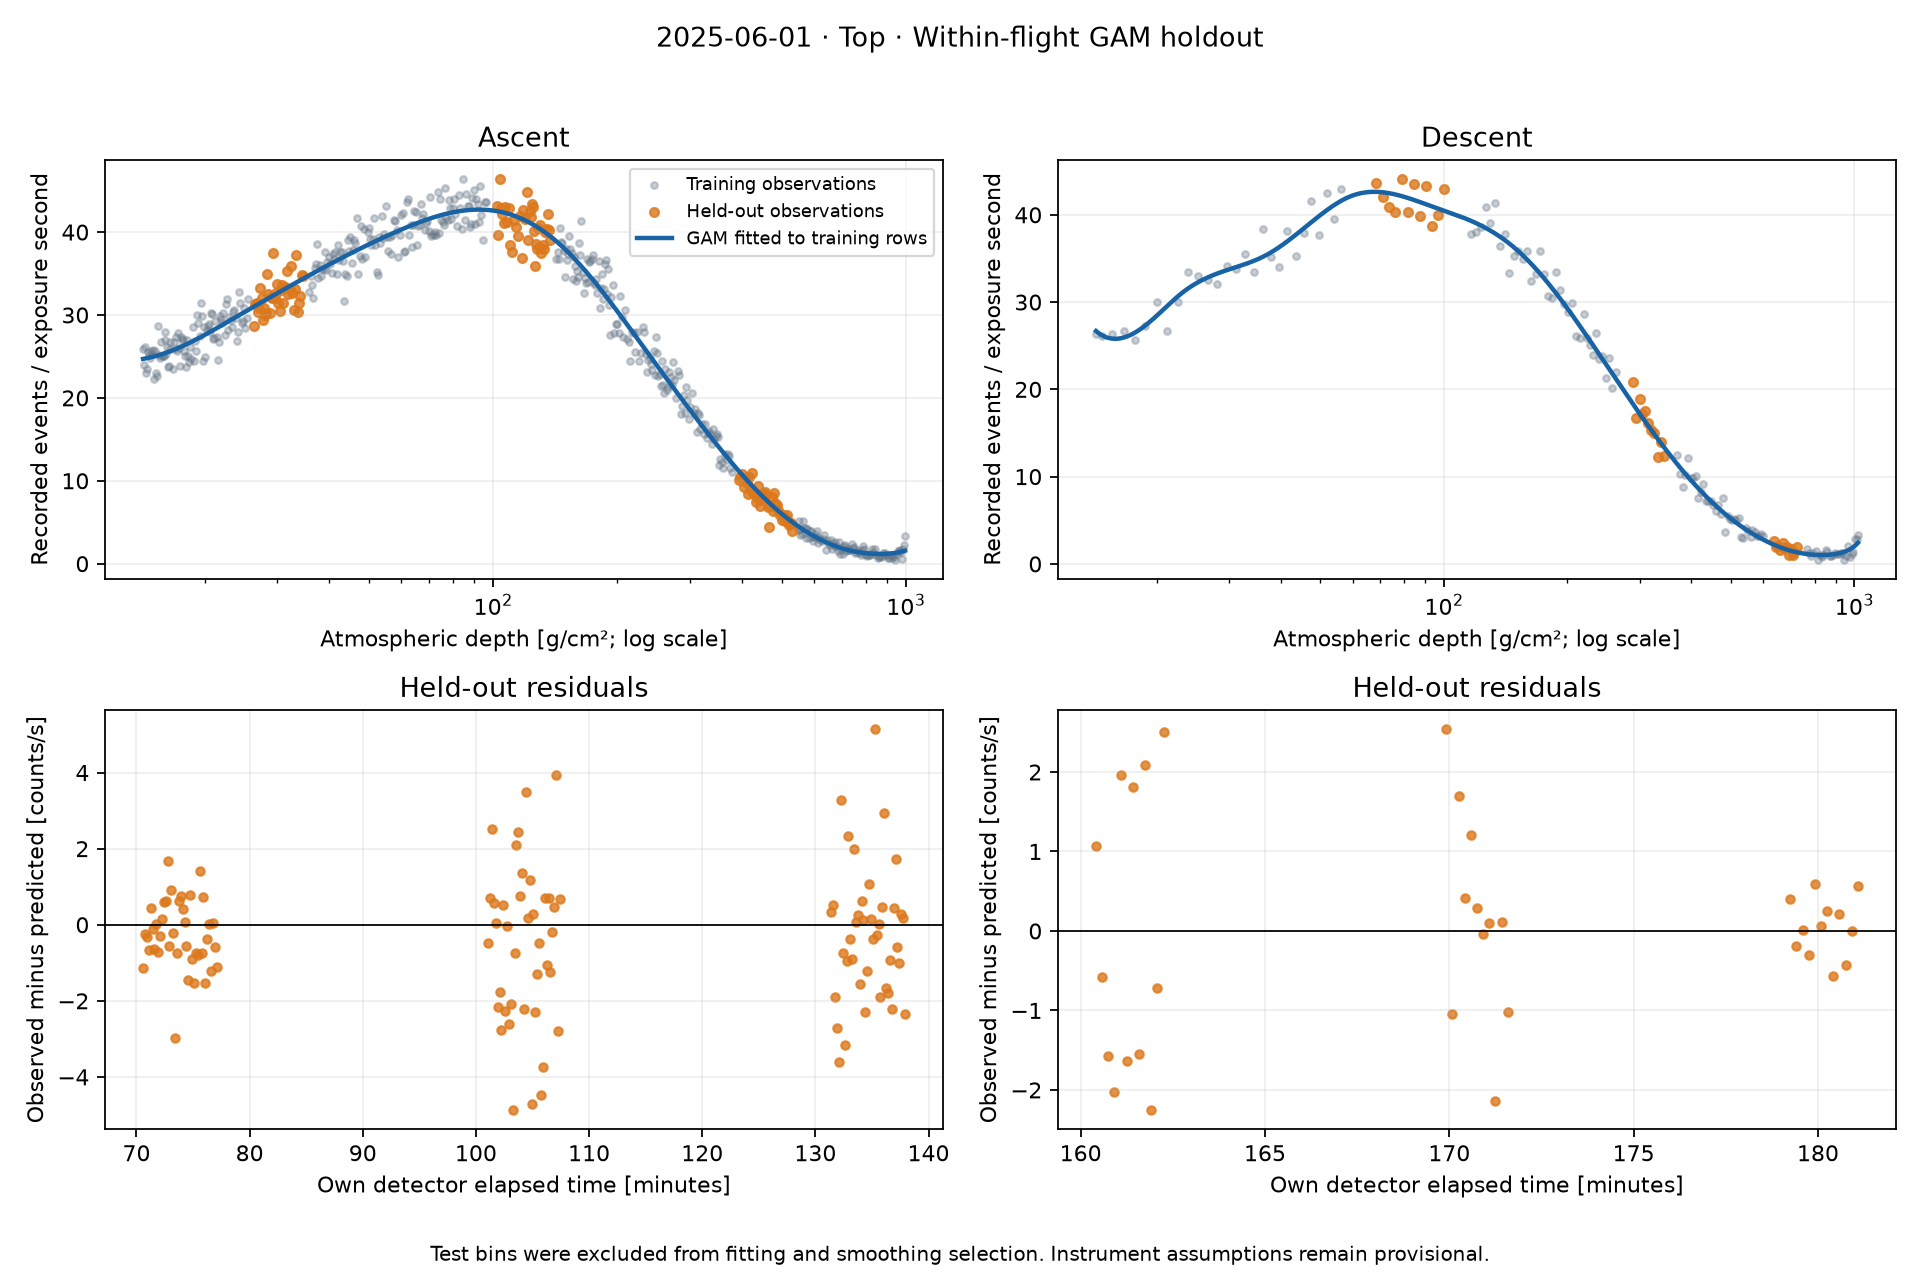

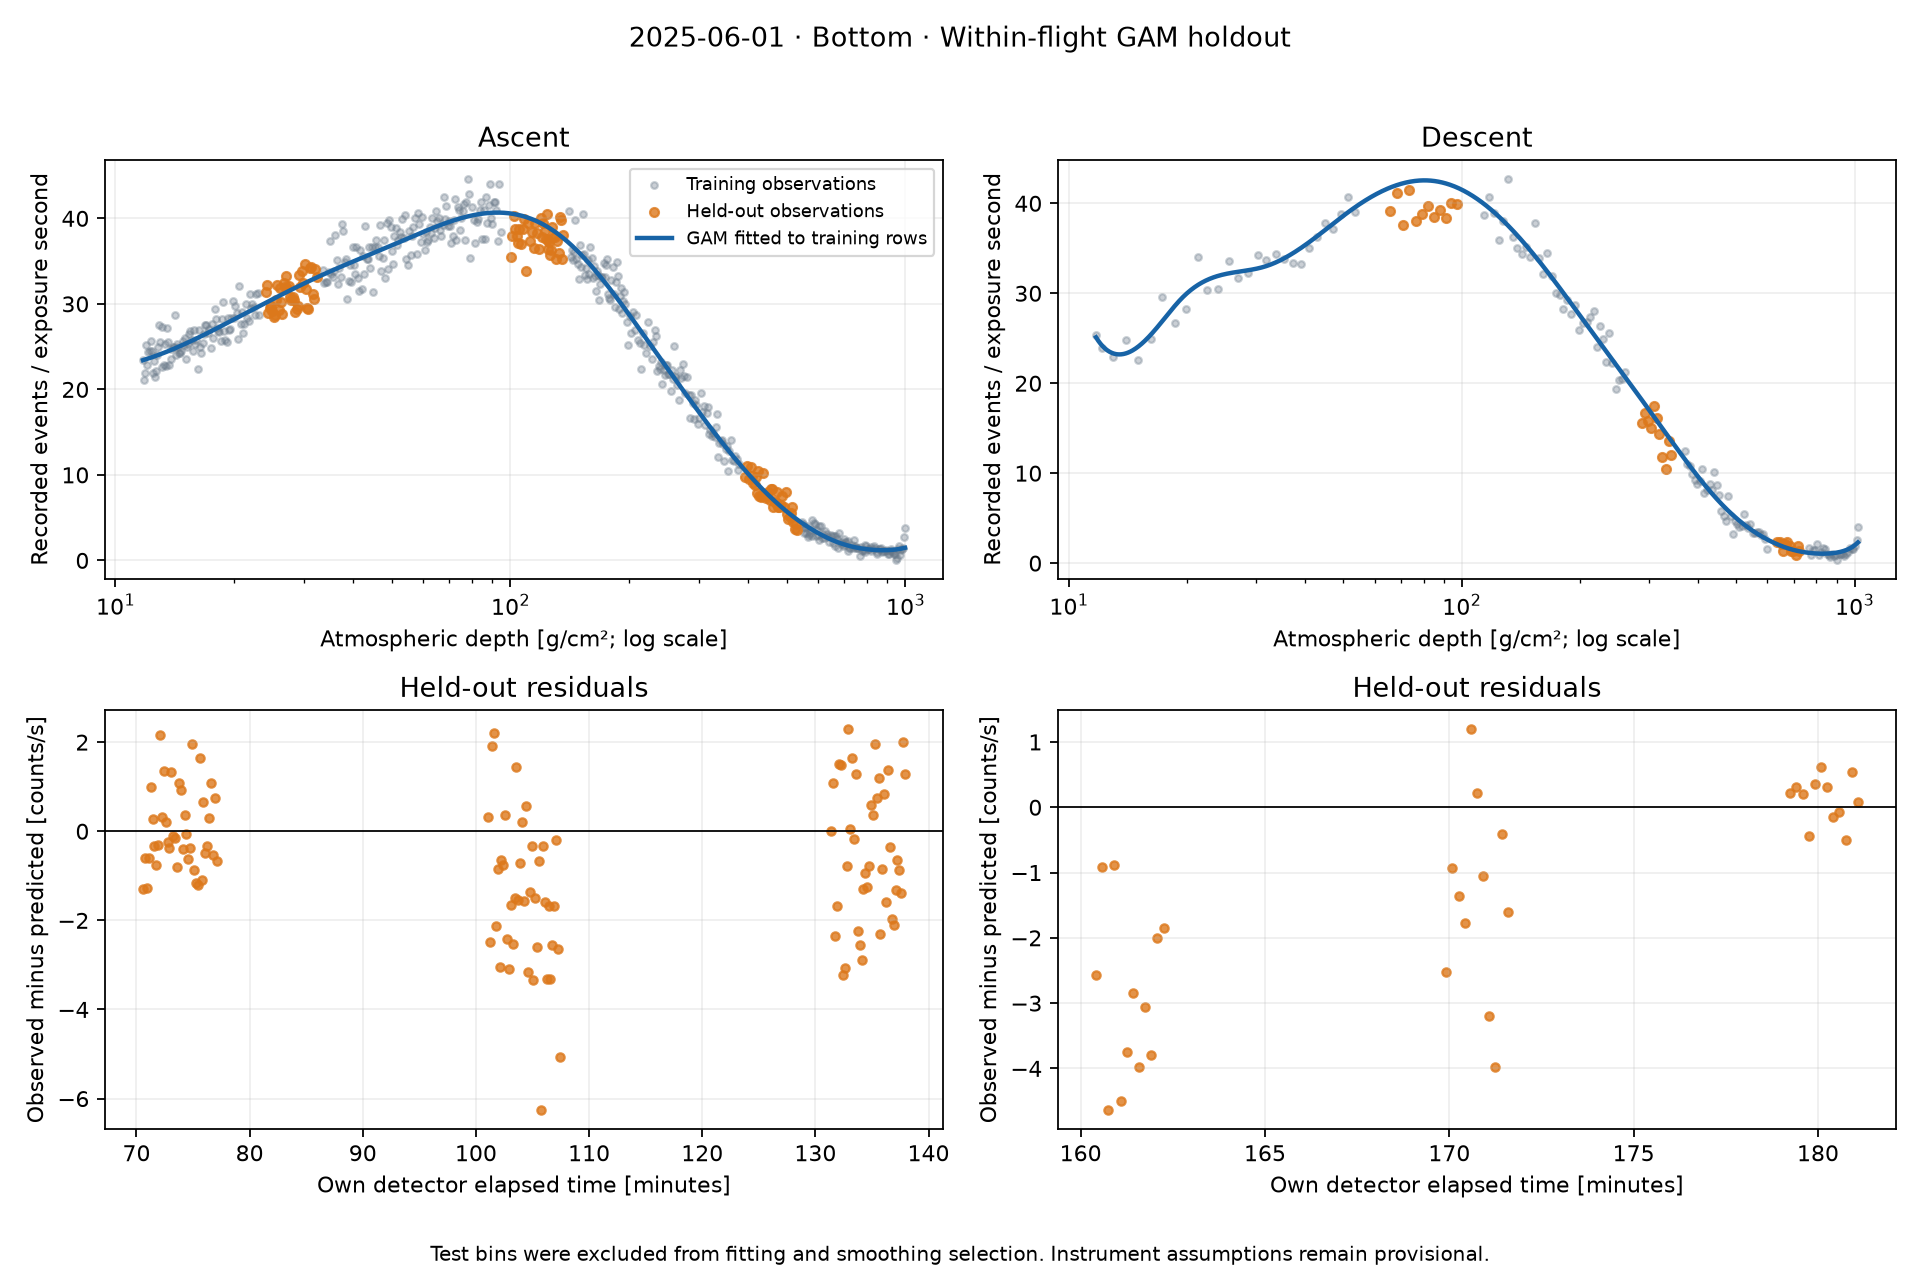

Finished. Results: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\results\2025-06-01\20261101T021517195014Z_gam_validation


In [9]:
for detector in settings["detectors"]:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for col, phase in enumerate(fit_profile.PHASES):
        part = predictions.loc[predictions.detector_id.eq(detector)
                               & predictions.phase_provisional.eq(phase)]
        train = part.loc[part.split_role.eq("train")]
        test = part.loc[part.split_role.eq("test")]
        curve = curves.loc[curves.detector_id.eq(detector)
                           & curves.phase_provisional.eq(phase)]
        ax = axes[0, col]
        ax.scatter(train.depth_g_cm2, train.observed_rate_cps, s=9, alpha=0.35,
                   color="#687888", label="Training observations")
        ax.scatter(test.depth_g_cm2, test.observed_rate_cps, s=16, alpha=0.8,
                   color="#dc781b", label="Held-out observations")
        ax.plot(curve.depth_g_cm2, curve.fitted_rate_cps, color="#1763a6", linewidth=2,
                label="GAM fitted to training rows")
        ax.set(xscale="log", title=phase.capitalize(),
               xlabel="Atmospheric depth [g/cm²; log scale]", ylabel="Recorded events / exposure second")
        residual_ax = axes[1, col]
        residual_ax.scatter((test.bin_start_s + test.bin_end_s) / 120, test.rate_residual_cps,
                            s=14, color="#dc781b", alpha=0.8)
        residual_ax.axhline(0, color="black", linewidth=0.8)
        residual_ax.set(title="Held-out residuals", xlabel="Own detector elapsed time [minutes]",
                        ylabel="Observed minus predicted [counts/s]")
    axes[0, 0].legend(fontsize=8)
    for ax in axes.flat:
        ax.grid(alpha=0.2)
    fig.suptitle(f"{settings['flight_id']} · {detector.capitalize()} · Within-flight GAM holdout")
    fig.text(0.5, 0.015, "Test bins were excluded from fitting and smoothing selection. Instrument assumptions remain provisional.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.045, 1, 0.96))
    plot_path = RUN_DIR / f"{detector}_validation.png"
    fig.savefig(plot_path, dpi=160)
    plt.close(fig)
    display(Image(filename=str(plot_path), width=1000))
manifest["status"] = "complete"
save_manifest()
print("Finished. Results:", RUN_DIR)

## What comes after this

Review test errors and residuals against the constant-rate reference. Investigate
large errors using the existing quality flags, pressure range and flight records.
Keep this benchmark fixed when comparing algorithms. Do not repeatedly adjust
the split or hyperparameters in response to its test scores.

For further model development, use blocked validation **inside the training
portion**, then evaluate on a genuinely separate flight when available. Reusing
June 1 to develop the pipeline does not establish performance on unseen flights.
This notebook also does not validate pressure calibration, acquisition continuity,
detector response, timing, or the physical peak's location.

For review, attach **test_metrics.csv** and the detector validation plots. All
outputs are printed above and saved under the new `_gam_validation` folder.
Before committing this notebook, clear its outputs and save.

References: [pyGAM PoissonGAM](https://pygam.readthedocs.io/en/latest/reference/_autosummary/pygam.pygam.PoissonGAM.html),
[scikit-learn validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html),
[XGBoost exposure offsets](https://xgboost.readthedocs.io/en/stable/tutorials/intercept.html#offset).